# 10 · Figures of the report

Draws Figures 1–8 of the report.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    P = Path("/content/drive/MyDrive/Affective Project/predictions")
else:
    P = Path("../predictions")

FILES = {
    "audio_v2_test": P / "audio_v2_test_predictions.csv",
    "audio_v2_validation": P / "audio_v2_validation_predictions.csv",
    "audio_v1_validation": P / "audio_v1_validation_predictions.csv",
    "audio_v2_history": P / "audio_v2_history.csv",
    "visual_test": P / "visual_test_predictions.csv",
    "visual_validation": P / "visual_validation_predictions.csv",
}
missing = [str(p) for p in FILES.values() if not p.exists()]
assert not missing, "Missing files:\n" + "\n".join(missing)
for k, p in FILES.items():
    print(f"{k:22s} {p}")

Mounted at /content/drive
audio_v2_test          /content/drive/MyDrive/Affective Project/predictions/audio_v2_test_predictions.csv
audio_v2_validation    /content/drive/MyDrive/Affective Project/predictions/audio_v2_validation_predictions.csv
audio_v1_validation    /content/drive/MyDrive/Affective Project/predictions/audio_v1_validation_predictions.csv
audio_v2_history       /content/drive/MyDrive/Affective Project/predictions/audio_v2_history.csv
visual_test            /content/drive/MyDrive/Affective Project/predictions/visual_test_predictions.csv
visual_validation      /content/drive/MyDrive/Affective Project/predictions/visual_validation_predictions.csv


In [2]:
D = Path("/content/drive/MyDrive/Affective Project/data") if IN_COLAB else Path("../data")
DATA = {"ratings": D / "summaryTable.csv", "actors": D / "VideoDemographics.csv"}
missing = [str(p) for p in DATA.values() if not p.exists()]
assert not missing, "Missing files:\n" + "\n".join(missing)

In [3]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def have_inter():
    return any(f.name == "Inter" for f in fm.fontManager.ttflist)

if not have_inter():
    import subprocess, glob
    if IN_COLAB:
        subprocess.run("apt-get -qq install -y fonts-inter > /dev/null", shell=True)
    for f in glob.glob("/usr/share/fonts/**/Inter*", recursive=True):
        fm.fontManager.addfont(f)
print("Inter font available:", have_inter())

OUT = Path("/content/drive/MyDrive/Affective Project/figures") if IN_COLAB else Path("../figures")
OUT.mkdir(parents=True, exist_ok=True)
print("Figures are saved to:", OUT)
import matplotlib.pyplot as plt

AUD, AUD_L = "#e4572e", "#f6c3b0"     # audio: vermilion
VIS, VIS_L = "#2563b8", "#b9cdee"     # visual: blue
FUS = "#16946b"                       # fusion: green
HUM = "#6b6a66"                       # humans: grey
INK, INK2, INK3, GRID = "#1a1a1a", "#4d4d4d", "#8c8c8c", "#e6e6e6"
EMO = ["Anger", "Disgust", "Fear", "Happiness", "Neutral", "Sadness"]
CODES = ["Anger", "Disgust", "Fear", "Happy", "Neutral", "Sad"]

plt.rcParams.update({
    "font.family": "Inter", "font.size": 8.5,
    "axes.titlesize": 9, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 8, "axes.labelsize": 8.5, "axes.labelcolor": INK2,
    "axes.edgecolor": INK3, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 7.8, "ytick.labelsize": 7.8,
    "xtick.major.size": 3, "ytick.major.size": 0, "xtick.major.width": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 7.8,
    "figure.dpi": 300, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.04,
    "lines.solid_capstyle": "round",
})


def panel(ax, letter, x=-0.11, y=1.06):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10, fontweight="bold", color=INK, va="bottom")

Inter font available: True
Figures are saved to: /content/drive/MyDrive/Affective Project/figures


In [4]:
CLASSES = ["Anger", "Disgust", "Fear", "Happy", "Neutral", "Sad"]
PROB = [f"prob_{c}" for c in CLASSES]


def load_split(split):
    """One row per clip: true label and both models' predictions and probabilities.
    Clips without a visual prediction are dropped (only 1076_MTI_SAD_XX in validation)."""
    v = pd.read_csv(FILES[f"visual_{split}"])
    v = v[v["status"] == "ok"]
    a = pd.read_csv(FILES[f"audio_v2_{split}"])
    a["video_id"] = a["filename"].str.replace(".wav", "", regex=False)
    m = v[["video_id", "Speaker", "true_label", "predicted_label", *PROB]].merge(
        a[["video_id", "true_label", "predicted_label", *PROB]],
        on="video_id", suffixes=("_v", "_a"), validate="one_to_one")
    assert (m["true_label_v"] == m["true_label_a"]).all(), "label mismatch"
    m = m.rename(columns={"true_label_v": "y", "predicted_label_v": "pred_v",
                          "predicted_label_a": "pred_a"}).drop(columns="true_label_a")
    return m


def ece(p, y_idx, bins=10):
    """Expected calibration error with 10 equal-width confidence bins."""
    conf, pred = p.max(1), p.argmax(1)
    correct = (pred == y_idx).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = (conf > lo) & (conf <= hi)
        if s.any():
            total += s.mean() * abs(conf[s].mean() - correct[s].mean())
    return total

In [5]:
CODE = {"A": "Anger", "D": "Disgust", "F": "Fear", "H": "Happy", "N": "Neutral", "S": "Sad"}


def add_human_ratings(df):
    s = pd.read_csv(DATA["ratings"], dtype=str).rename(columns={"FileName": "video_id"})
    df = df.merge(s[["video_id", "VoiceVote", "FaceVote", "MultiModalVote"]],
                  on="video_id", how="left", validate="one_to_one")
    assert df.VoiceVote.notna().all()
    for col, new in [("VoiceVote", "h_voice"), ("FaceVote", "h_face"), ("MultiModalVote", "h_av")]:
        df[new] = df[col].map(lambda x: frozenset(CODE[c] for c in x.split(":")))
        df[new + "_correct"] = [y in s for y, s in zip(df.y, df[new])]
    df["human_disagree"] = [len(a & b) == 0 for a, b in zip(df.h_voice, df.h_face)]
    return df

In [6]:
from scipy.optimize import minimize_scalar
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

K, EPS = len(CLASSES), 1e-12


def to_arrays(df):
    return dict(pv=df[[f"{p}_v" for p in PROB]].to_numpy(float),
                pa=df[[f"{p}_a" for p in PROB]].to_numpy(float),
                y=np.array([CLASSES.index(c) for c in df.y]),
                speaker=df.Speaker.to_numpy())


def subset(d, idx):
    return {k: v[idx] for k, v in d.items()}


def nll(p, y):
    return -np.mean(np.log(p[np.arange(len(y)), y] + EPS))


def temp_scale(p, T):
    z = np.log(p + EPS) / T
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def fit_temperature(p, y):
    return float(minimize_scalar(lambda T: nll(temp_scale(p, T), y), bounds=(0.05, 20), method="bounded").x)


def features(pv, pa):
    """Stacking input (16 numbers per clip): 6 + 6 log-probabilities, disagreement flag,
    confidence of each model and the difference of the confidences."""
    lv, la = np.log(pv + EPS), np.log(pa + EPS)
    dis = (pv.argmax(1) != pa.argmax(1)).astype(float)[:, None]
    cv, ca = pv.max(1, keepdims=True), pa.max(1, keepdims=True)
    return np.hstack([lv, la, dis, cv, ca, cv - ca])


def fit_methods(fit):
    """Learn every fusion method on the fit data; return a predict function."""
    pv, pa, y = fit["pv"], fit["pa"], fit["y"]
    Tv, Ta = fit_temperature(pv, y), fit_temperature(pa, y)
    cv, ca = temp_scale(pv, Tv), temp_scale(pa, Ta)
    grid = np.linspace(0, 1, 21)
    w = grid[np.argmax([accuracy_score(y, (g * cv + (1 - g) * ca).argmax(1)) for g in grid])]

    def precision(p):
        pred = p.argmax(1)
        return np.array([(y[pred == k] == k).mean() if (pred == k).any() else 0 for k in range(K)])
    prec_v, prec_a = precision(cv), precision(ca)

    clf = LogisticRegression(C=1.0, max_iter=2000).fit(features(cv, ca), y)
    params = dict(T_visual=Tv, T_audio=Ta, w_visual=float(w))

    def predict(ev):
        ev_cv, ev_ca = temp_scale(ev["pv"], Tv), temp_scale(ev["pa"], Ta)
        yv, ya = ev_cv.argmax(1), ev_ca.argmax(1)
        out = {
            "Visual only": yv,
            "Audio only": ya,
            "Average (raw)": (ev["pv"] + ev["pa"]).argmax(1),
            "Product": (np.log(ev["pv"] + EPS) + np.log(ev["pa"] + EPS)).argmax(1),
            "Weighted average": (w * ev_cv + (1 - w) * ev_ca).argmax(1),
            "Most confident": np.where(ev["pv"].max(1) >= ev["pa"].max(1), ev["pv"].argmax(1), ev["pa"].argmax(1)),
            "Most confident (cal.)": np.where(ev_cv.max(1) >= ev_ca.max(1), yv, ya),
            "Per-class trust rule": np.where(yv != ya, np.where(prec_v[yv] >= prec_a[ya], yv, ya), yv),
            "Stacking": clf.predict(features(ev_cv, ev_ca)),
            "Upper bound": np.where(yv == ev["y"], yv, ya),
        }
        return out, ev_cv, ev_ca
    return predict, params

In [7]:
def speaker_bootstrap(y, a, b, speakers, n=2000, seed=0):
    """95% CI of the accuracy difference a - b, resampling whole speakers."""
    rng = np.random.default_rng(seed)
    spk = np.unique(speakers)
    idx_by = {s: np.where(speakers == s)[0] for s in spk}
    diffs = []
    for _ in range(n):
        idx = np.concatenate([idx_by[s] for s in rng.choice(spk, len(spk))])
        diffs.append((a[idx] == y[idx]).mean() - (b[idx] == y[idx]).mean())
    return np.percentile(diffs, [2.5, 97.5])


def mcnemar(y, a, b):
    ok_a, ok_b = a == y, b == y
    n10, n01 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return n10, n01, binomtest(n10, n10 + n01, 0.5).pvalue

## Numbers used in the figures

In [8]:
from scipy.stats import binomtest
from sklearn.metrics import f1_score

val, m = load_split("validation"), load_split("test")
m = add_human_ratings(m)
m["cv"], m["ca"] = m.pred_v == m.y, m.pred_a == m.y
m["dis"] = m.pred_v != m.pred_a

# Figure 4: disagreement rates and what the model disagreements are
dis = pd.DataFrame({"model_disagreement": m.groupby("y").dis.mean(),
                    "human_disagreement": m.groupby("y").human_disagree.mean()}).loc[CODES] * 100
d = m[m.dis].copy()
d["mirrored"] = [a in hv and v in hf for a, v, hv, hf in zip(d.pred_a, d.pred_v, d.h_voice, d.h_face)]
d["category"] = np.where(~d.human_disagree, "Model error",
                 np.where(d.mirrored, "Same labels as humans", "Humans also disagree"))
cat = pd.crosstab(d.y, d.category).loc[CODES]

# Figure 5: recall of models and human raters per emotion
acc = pd.DataFrame({"Audio model": m.groupby("y").ca.mean(), "Humans, voice only": m.groupby("y").h_voice_correct.mean(),
                    "Visual model": m.groupby("y").cv.mean(), "Humans, face only": m.groupby("y").h_face_correct.mean()
                    }).loc[CODES] * 100

# Figure 6: F1 difference with speaker-bootstrap CI, McNemar test (Holm), who is right
rng = np.random.default_rng(0)
speakers = m.Speaker.unique()
idx_by = {s: np.where(m.Speaker.values == s)[0] for s in speakers}
diffs = []
for _ in range(2000):
    g = m.iloc[np.concatenate([idx_by[s] for s in rng.choice(speakers, len(speakers))])]
    diffs.append(f1_score(g.y, g.pred_v, labels=CODES, average=None) - f1_score(g.y, g.pred_a, labels=CODES, average=None))
ci = np.percentile(diffs, [2.5, 97.5], axis=0)
rows = []
for k, c in enumerate(CODES):
    g = m[m.y == c]
    n10, n01 = int((g.cv & ~g.ca).sum()), int((~g.cv & g.ca).sum())
    rows.append(dict(emotion=c, f1_diff_v_minus_a=f1_score(m.y, m.pred_v, labels=[c], average=None)[0]
                     - f1_score(m.y, m.pred_a, labels=[c], average=None)[0],
                     ci_low=ci[0, k], ci_high=ci[1, k], only_visual_right=n10, only_audio_right=n01,
                     mcnemar_p=binomtest(n10, n10 + n01, 0.5).pvalue,
                     dis_neither=int((g.dis & ~g.cv & ~g.ca).sum()), n_dis=int(g.dis.sum())))
r3 = pd.DataFrame(rows).set_index("emotion")
order_p, running, holm = np.argsort(r3.mcnemar_p.values), 0, np.empty(6)
for i, j in enumerate(order_p):
    running = max(running, min(1, (6 - i) * r3.mcnemar_p.values[j])); holm[j] = running
r3["mcnemar_p_holm"] = holm

# Figure 7: accuracy per speaker and better modality per emotion
sp = m.groupby("Speaker").agg(acc_v=("cv", "mean"), acc_a=("ca", "mean")).reset_index()
sp["diff_v_minus_a"] = sp.acc_v - sp.acc_a
sp["mcnemar_p"] = [binomtest(int((g.cv & ~g.ca).sum()), int((g.cv != g.ca).sum()), 0.5).pvalue
                   if (g.cv != g.ca).any() else 1.0 for _, g in m.groupby("Speaker")]
sp = sp.sort_values("acc_v").reset_index(drop=True)
rec = m.groupby(["Speaker", "y"])[["cv", "ca"]].mean()
se = (rec.cv - rec.ca).unstack()[CODES]
cons = pd.DataFrame({"visual_better": (se > 0).sum(), "audio_better": (se < 0).sum(), "tie": (se == 0).sum()})

# Figure 8: calibration and fusion methods (learned on the validation set)
va, te = to_arrays(val), to_arrays(m)
preds, cal_v, cal_a = fit_methods(va)[0](te)
res = pd.DataFrame({"accuracy": {k: (p == te["y"]).mean() for k, p in preds.items()}})
cal = pd.DataFrame([dict(model=mod, stage=st, mean_conf=p.max(1).mean(), accuracy=(p.argmax(1) == te["y"]).mean())
                    for mod, raw, c in [("Visual", te["pv"], cal_v), ("Audio", te["pa"], cal_a)]
                    for st, p in [("raw", raw), ("calibrated", c)]])
print("Model disagreement (%):", dis.model_disagreement.round(1).to_dict())
print("Stacking accuracy: %.1f%%" % (100 * res.loc["Stacking", "accuracy"]))

Model disagreement (%): {'Anger': 48.7, 'Disgust': 50.9, 'Fear': 52.8, 'Happy': 36.2, 'Neutral': 42.7, 'Sad': 74.7}
Stacking accuracy: 81.8%


## Figure 2: training curves

Audio model: `audio_v2_history.csv` (notebook 03). Visual model: the training
history printed in notebook 04 (stage 1 epochs 1–3, then stage 2 epochs 1–6).

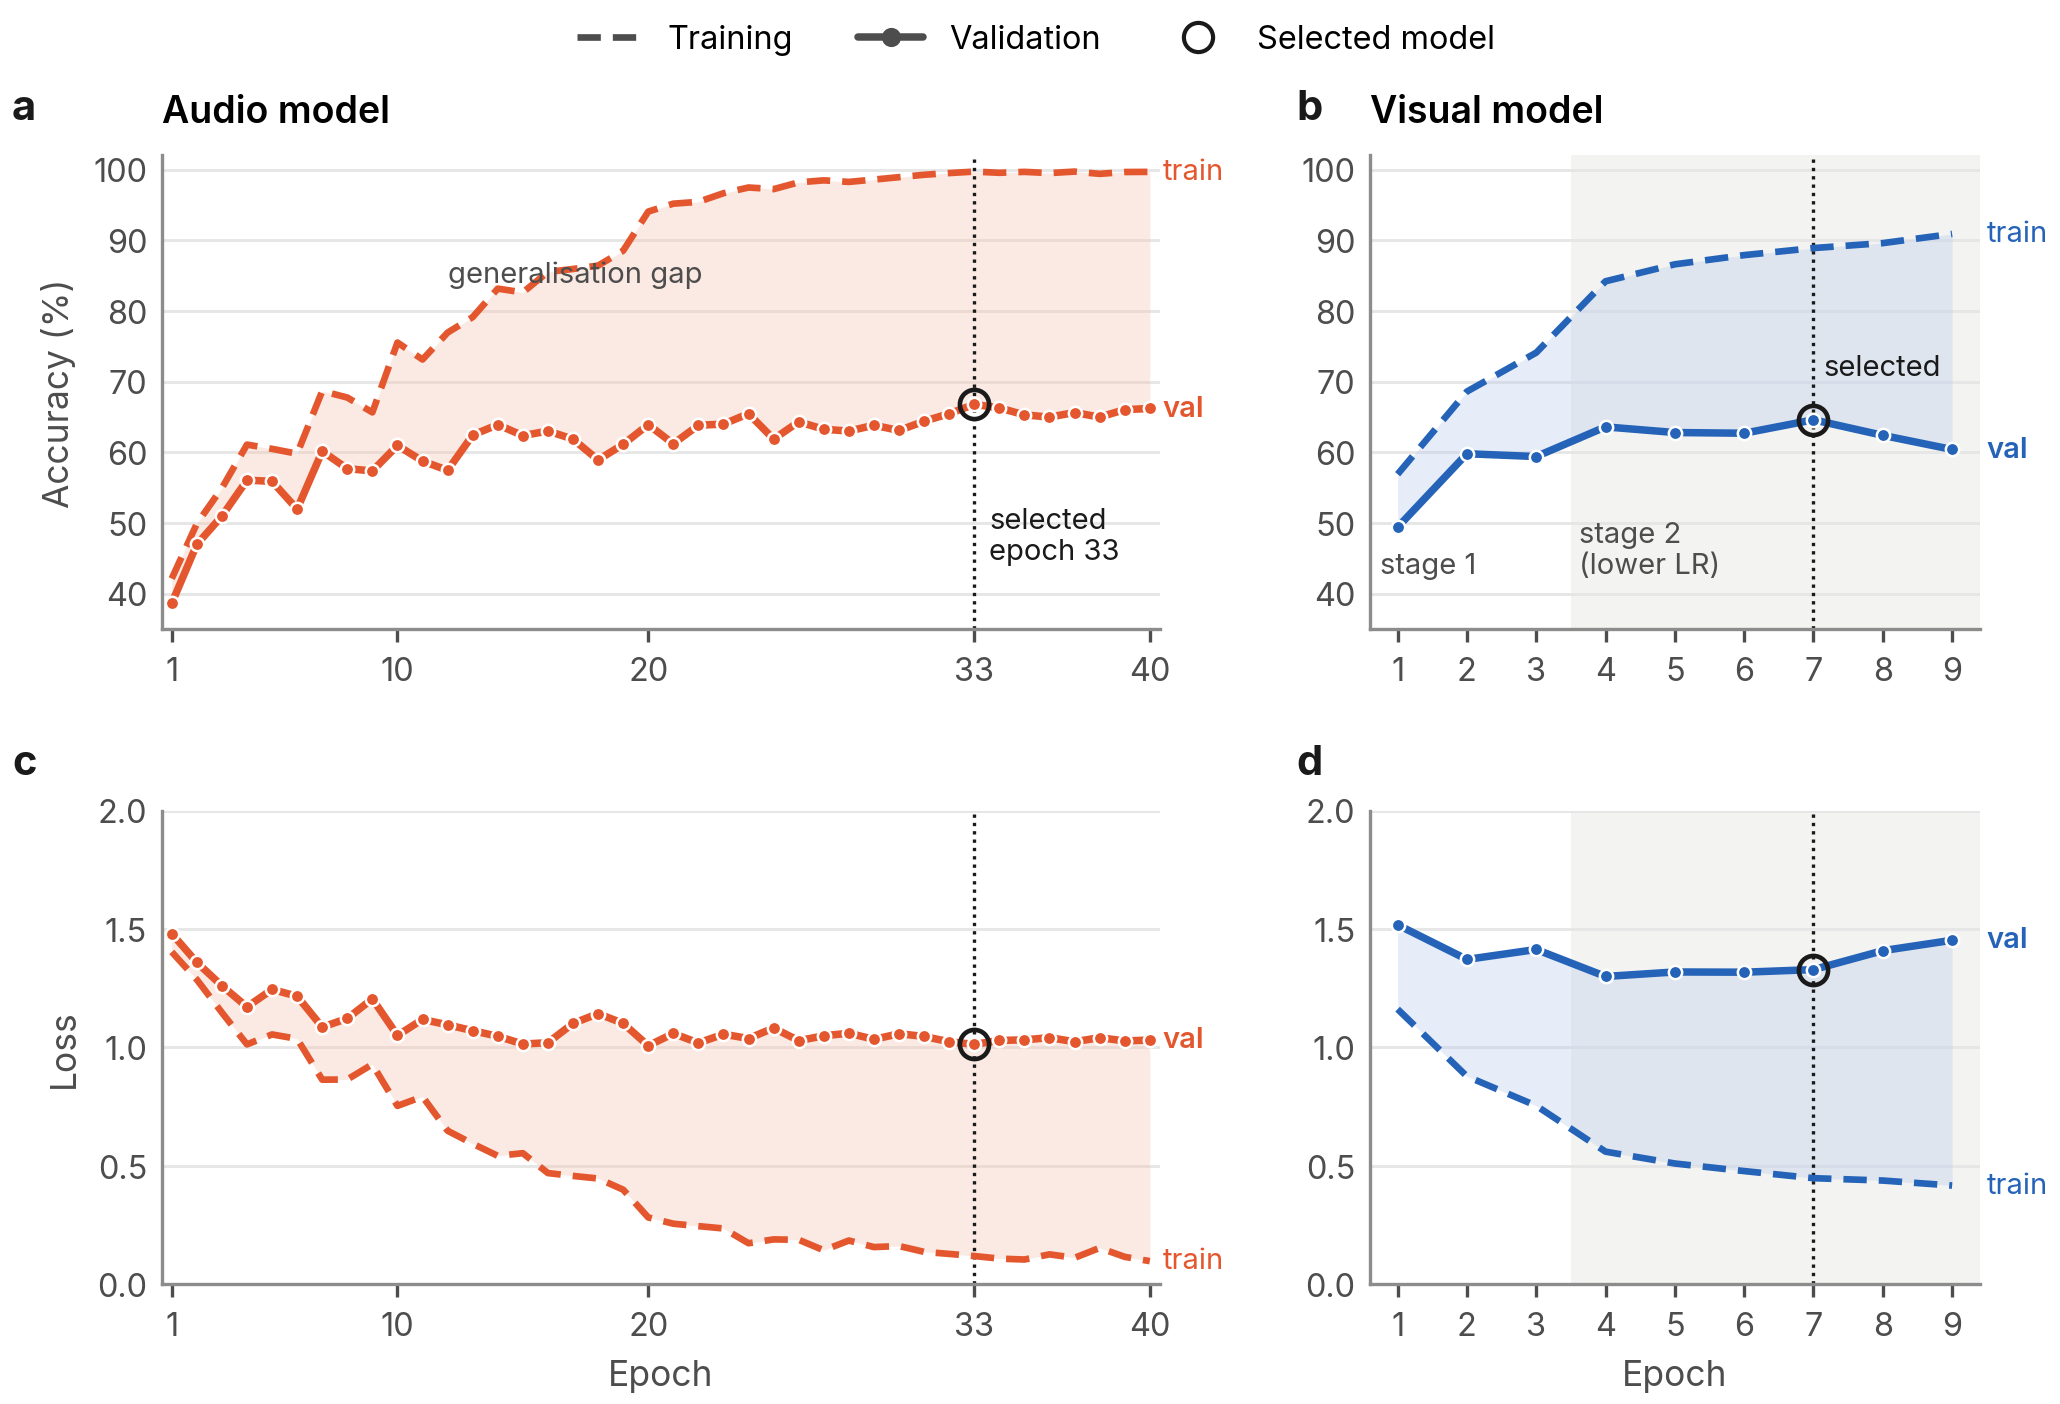

In [9]:
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

h = pd.read_csv(FILES["audio_v2_history"]).round(4)
A = dict(tr_acc=h.train_accuracy.tolist(), va_acc=h.val_accuracy.tolist(),
         tr_loss=h.train_loss.tolist(), va_loss=h.val_loss.tolist())
# visual: stage 1 epochs 1-3, then stage 2 (started from epoch 3) as epochs 4-9
V = dict(tr_acc=[.569,.686,.741] + [.842,.866,.879,.889,.896,.909],
         va_acc=[.494,.598,.594] + [.636,.628,.627,.646,.624,.604],
         tr_loss=[1.162,.878,.754] + [.560,.510,.478,.448,.438,.417],
         va_loss=[1.518,1.372,1.414] + [1.300,1.319,1.318,1.329,1.409,1.453])

fig, axs = plt.subplots(2, 2, figsize=(7.0, 4.6), gridspec_kw=dict(width_ratios=[18, 11]))
specs = [(A, AUD, AUD_L, 33, np.arange(1, 41), "Audio model"), (V, VIS, VIS_L, 7, np.arange(1, 10), "Visual model")]
for c, (D, col, coll, best, e, title) in enumerate(specs):
    for r, (key, scale, ylab, ylim) in enumerate([("acc", 100, "Accuracy (%)", (35, 102)), ("loss", 1, "Loss", (0, 2.0))]):
        ax = axs[r, c]
        tr, va = np.array(D["tr_" + key]) * scale, np.array(D["va_" + key]) * scale
        ax.fill_between(e, tr, va, color=coll, alpha=0.35, lw=0)
        ax.plot(e, tr, color=col, lw=1.6, ls=(0, (3.5, 1.8)))
        ax.plot(e, va, color=col, lw=1.8, marker="o", ms=3.2, mec="white", mew=0.6)
        ax.axvline(best, color=INK, lw=0.8, ls=(0, (1, 1.5)), zorder=1)
        ax.plot(best, va[best - 1], marker="o", ms=7, mfc="none", mec=INK, mew=1.1, zorder=5)
        ax.set_ylim(*ylim); ax.set_xlim(e[0] - 0.4, e[-1] + 0.4)
        ax.set_xticks([1, 10, 20, 33, 40] if c == 0 else range(1, 10))
        if c == 0: ax.set_ylabel(ylab)
        if r == 1: ax.set_xlabel("Epoch")
        if c == 1:
            ax.axvspan(3.5, 9.4, color="#f3f3f1", zorder=0, lw=0)
        if r == 0:
            ax.set_title(title)
        # end labels
        ax.text(e[-1] + 0.5, tr[-1], "train", color=col, fontsize=7, va="center", ha="left")
        ax.text(e[-1] + 0.5, va[-1], "val", color=col, fontsize=7, va="center", ha="left", fontweight="semibold")
axs[0, 0].text(33.6, 44, "selected\nepoch 33", fontsize=7, color=INK, ha="left", va="bottom")
axs[0, 1].text(7.15, 70, "selected", fontsize=7, color=INK, ha="left", va="bottom")
axs[0, 1].text(3.62, 42, "stage 2\n(lower LR)", fontsize=7, color=INK2, va="bottom")
axs[0, 1].text(0.75, 42, "stage 1", fontsize=7, color=INK2, va="bottom")
axs[0, 0].text(12, 84, "generalisation gap", fontsize=7, color=INK2, rotation=0, ha="left")
for ax, l in zip(axs.flat, "abcd"):
    panel(ax, l, x=-0.15 if ax in axs[:, 0] else -0.12)
fig.legend(handles=[Line2D([], [], color=INK2, lw=1.6, ls=(0, (3.5, 1.8)), label="Training"),
                    Line2D([], [], color=INK2, lw=1.8, ls="-", marker="o", ms=3.6, mec=INK2, label="Validation"),
                    Line2D([], [], color=INK, lw=0, marker="o", ms=7, mfc="none", mec=INK, label="Selected model")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout(h_pad=1.6, w_pad=2.2)
fig.savefig(OUT / "fig2_training.png", facecolor="white")

## Figure 3: confusion matrices

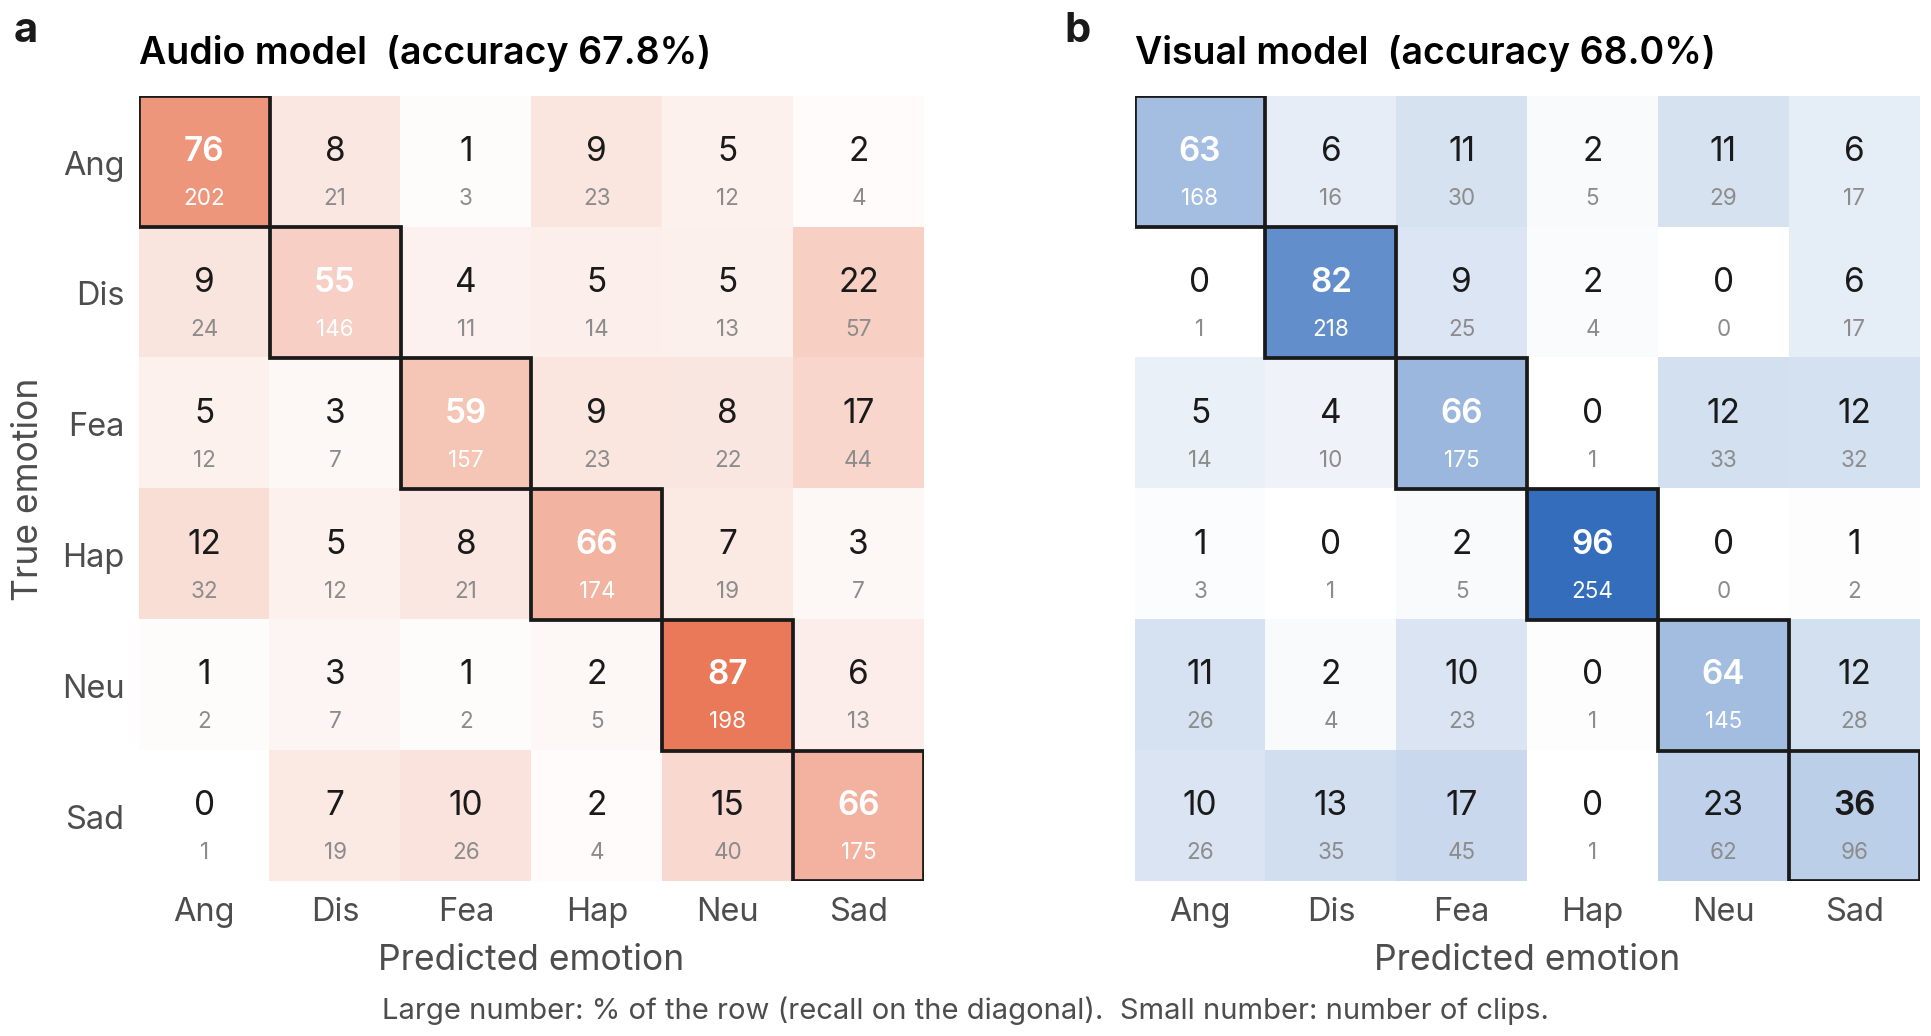

In [10]:
v = pd.read_csv(FILES["visual_test"])
a = pd.read_csv(FILES["audio_v2_test"])
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.35))
for k, (ax, df, col, title) in enumerate([(axs[0], a, AUD, "Audio model"), (axs[1], v, VIS, "Visual model")]):
    cm = pd.crosstab(df.true_label, df.predicted_label).reindex(index=CODES, columns=CODES, fill_value=0).values
    pct = cm / cm.sum(1, keepdims=True) * 100
    cmap = LinearSegmentedColormap.from_list("c", ["#ffffff", col + "33", col])
    ax.imshow(pct, cmap=cmap, vmin=0, vmax=100)
    ax.grid(False)
    for i in range(6):
        for j in range(6):
            ax.text(j, i - 0.08, f"{pct[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    fontweight=("semibold" if i == j else "normal"), color="white" if pct[i, j] > 55 else INK)
            ax.text(j, i + 0.28, f"{cm[i, j]}", ha="center", va="center", fontsize=5.4,
                    color="white" if pct[i, j] > 55 else INK3)
    for i in range(6):
        ax.add_patch(Rectangle((i - .5, i - .5), 1, 1, fc="none", ec=INK, lw=0.9))
    short = ["Ang", "Dis", "Fea", "Hap", "Neu", "Sad"]
    ax.set_xticks(range(6), short); ax.set_yticks(range(6), short if k == 0 else [])
    ax.set_xlabel("Predicted emotion")
    if k == 0: ax.set_ylabel("True emotion")
    ax.set_title(f"{title}  (accuracy {(np.trace(cm) / cm.sum() * 100):.1f}%)")
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    panel(ax, "ab"[k], x=-0.16 if k == 0 else -0.09)
fig.tight_layout(w_pad=0.8)
fig.text(0.5, -0.02, "Large number: % of the row (recall on the diagonal).  Small number: number of clips.",
         ha="center", fontsize=7, color=INK2)
fig.savefig(OUT / "fig3_confusion.png", facecolor="white")

## Figure 4: disagreement of models and human raters (RQ1)

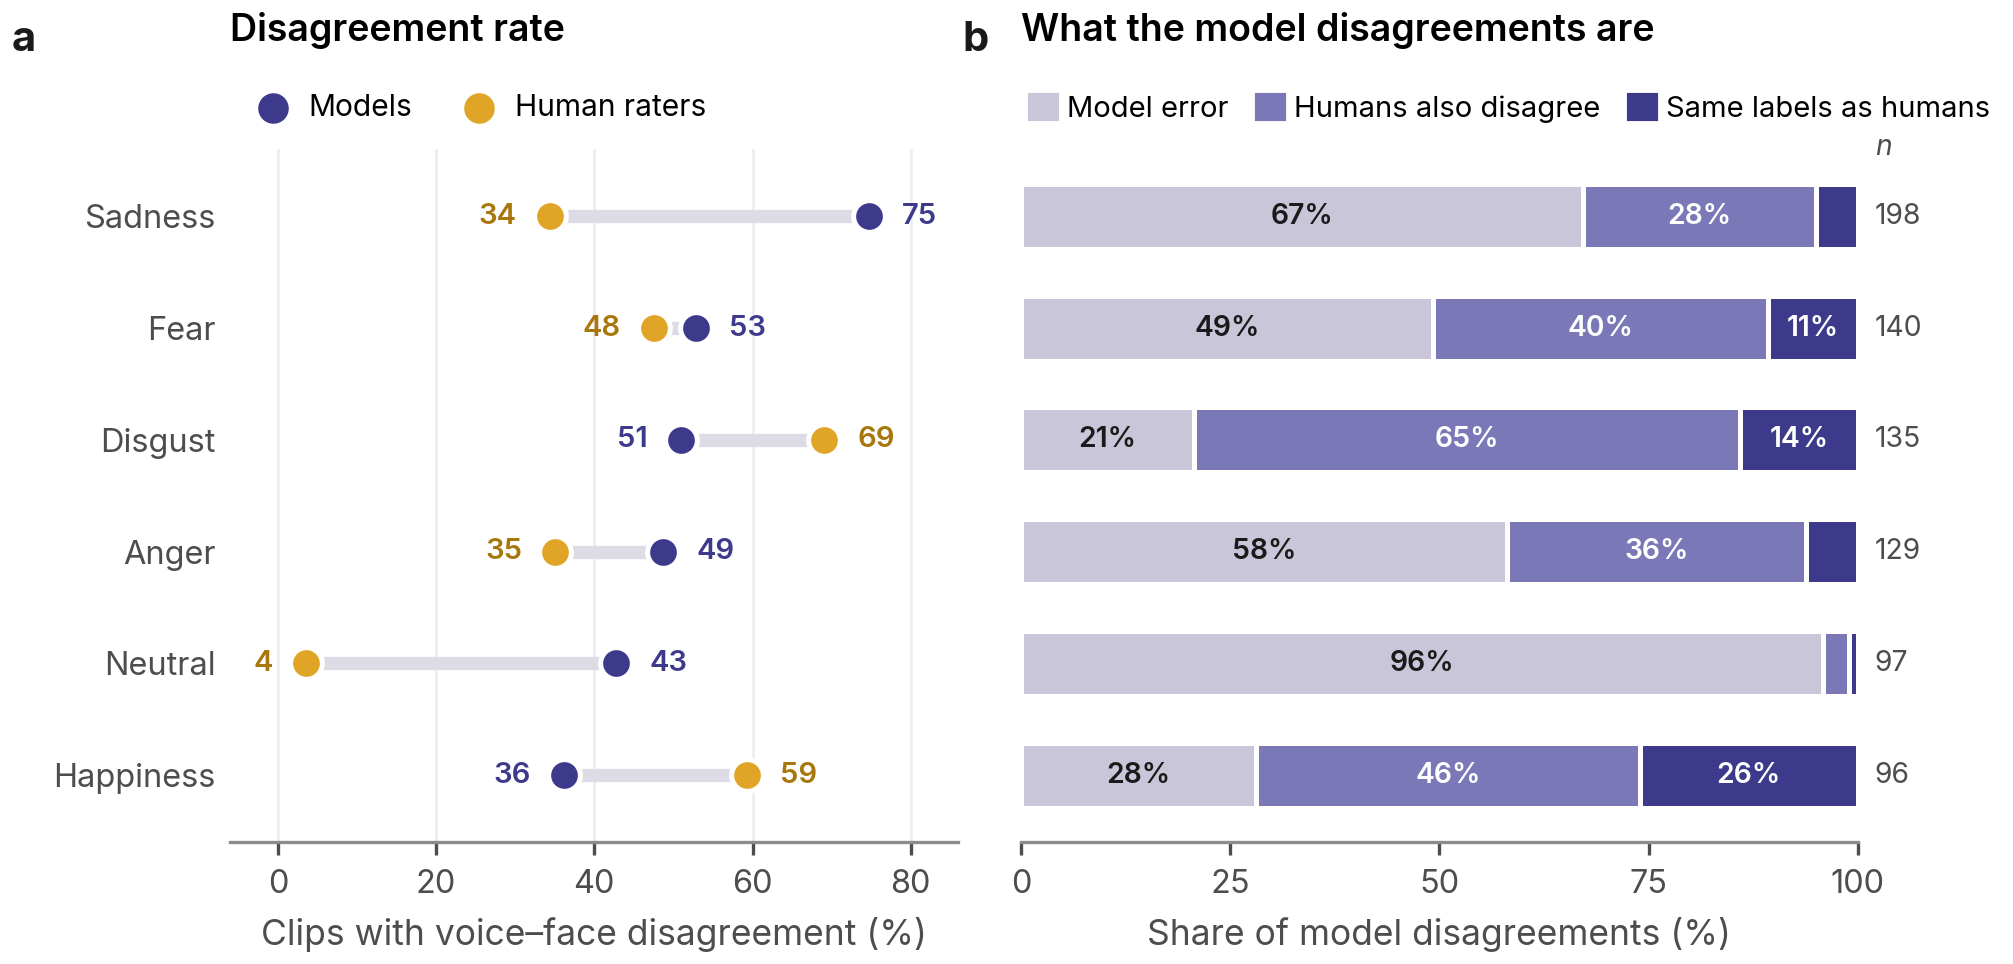

In [11]:
from matplotlib.patches import FancyBboxPatch
err, nmr, mir = "Model error", "Humans also disagree", "Same labels as humans"
lab = dict(zip(CODES, EMO))
order = dis.model_disagreement.sort_values().index

MOD, HUMC = "#3d3a8c", "#e0a526"           # models: indigo, humans: amber
C_ERR, C_BOTH, C_MIR = "#c9c6d9", "#7b78b8", "#3d3a8c"

fig = plt.figure(figsize=(7.0, 3.0))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=0.08)
axa, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
y = np.arange(len(order))

# (a) dumbbell: model vs human disagreement
for yi, e in zip(y, order):
    m, h = dis.loc[e, "model_disagreement"], dis.loc[e, "human_disagreement"]
    axa.plot([h, m], [yi, yi], color="#dcdbe6", lw=3.2, solid_capstyle="round", zorder=1)
    axa.scatter(m, yi, s=58, color=MOD, zorder=3, edgecolor="white", lw=1.2)
    axa.scatter(h, yi, s=58, color=HUMC, zorder=3, edgecolor="white", lw=1.2)
    off = 4.2
    axa.text(m + (off if m >= h else -off), yi, f"{m:.0f}", va="center", ha="left" if m >= h else "right",
             fontsize=7, color=MOD, fontweight="semibold")
    axa.text(h + (off if h > m else -off), yi, f"{h:.0f}", va="center", ha="left" if h > m else "right",
             fontsize=7, color="#a8770c", fontweight="semibold")
axa.set_yticks(y, [lab[e] for e in order]); axa.set_xlim(-6, 86); axa.set_ylim(-0.6, len(order) - 0.4)
axa.set_xticks([0, 20, 40, 60, 80])
axa.grid(axis="y", visible=False); axa.grid(axis="x", visible=True, color="#efeff3")
axa.spines["left"].set_visible(False); axa.tick_params(axis="y", length=0)
axa.set_xlabel("Clips with voice–face disagreement (%)")
axa.set_title("Disagreement rate", pad=26)
axa.scatter([], [], s=40, color=MOD, label="Models"); axa.scatter([], [], s=40, color=HUMC, label="Human raters")
axa.legend(loc="lower left", bbox_to_anchor=(-0.02, 1.0), ncol=2, fontsize=7.2, handletextpad=0.2, columnspacing=1.2)
panel(axa, "a", x=-0.3, y=1.13)

# (b) composition of model disagreements, rounded stacked bars
tot = cat.sum(axis=1)
parts = [(err, C_ERR, INK, "Model error"), (nmr, C_BOTH, "white", "Humans also disagree"),
         (mir, C_MIR, "white", "Same labels as humans")]
for yi, e in zip(y, order):
    left = 0
    vals = [cat.loc[e, c] / tot.loc[e] * 100 for c, *_ in parts]
    for (c, col, tc, _), v in zip(parts, vals):
        axb.barh(yi, v, 0.58, left=left, color=col, edgecolor="white", lw=1.2)
        if v >= 8:
            axb.text(left + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=6.8, color=tc,
                     fontweight="semibold")
        left += v
    axb.text(102, yi, f"{tot.loc[e]}", va="center", fontsize=6.8, color=INK2)
axb.text(102, len(order) - 0.45, "n", fontsize=6.8, color=INK2, fontstyle="italic")
axb.set_yticks(y, []); axb.set_xlim(0, 100); axb.set_ylim(-0.6, len(order) - 0.4)
axb.set_xticks([0, 25, 50, 75, 100])
axb.grid(axis="y", visible=False); axb.grid(axis="x", visible=False)
axb.spines["left"].set_visible(False); axb.tick_params(axis="y", length=0)
axb.set_xlabel("Share of model disagreements (%)")
axb.set_title("What the model disagreements are", pad=26)
from matplotlib.patches import Patch
axb.legend(handles=[Patch(color=col, label=l) for c, col, tc, l in parts], loc="lower left", bbox_to_anchor=(-0.02, 1.0), ncol=3, fontsize=7.0, handlelength=0.9,
           handleheight=0.9, handletextpad=0.35, columnspacing=1.0)
panel(axb, "b", x=-0.07, y=1.13)

fig.savefig(OUT / "fig4_disagreement.png", facecolor="white")

## Figure 5: recall of models and human raters (RQ2)

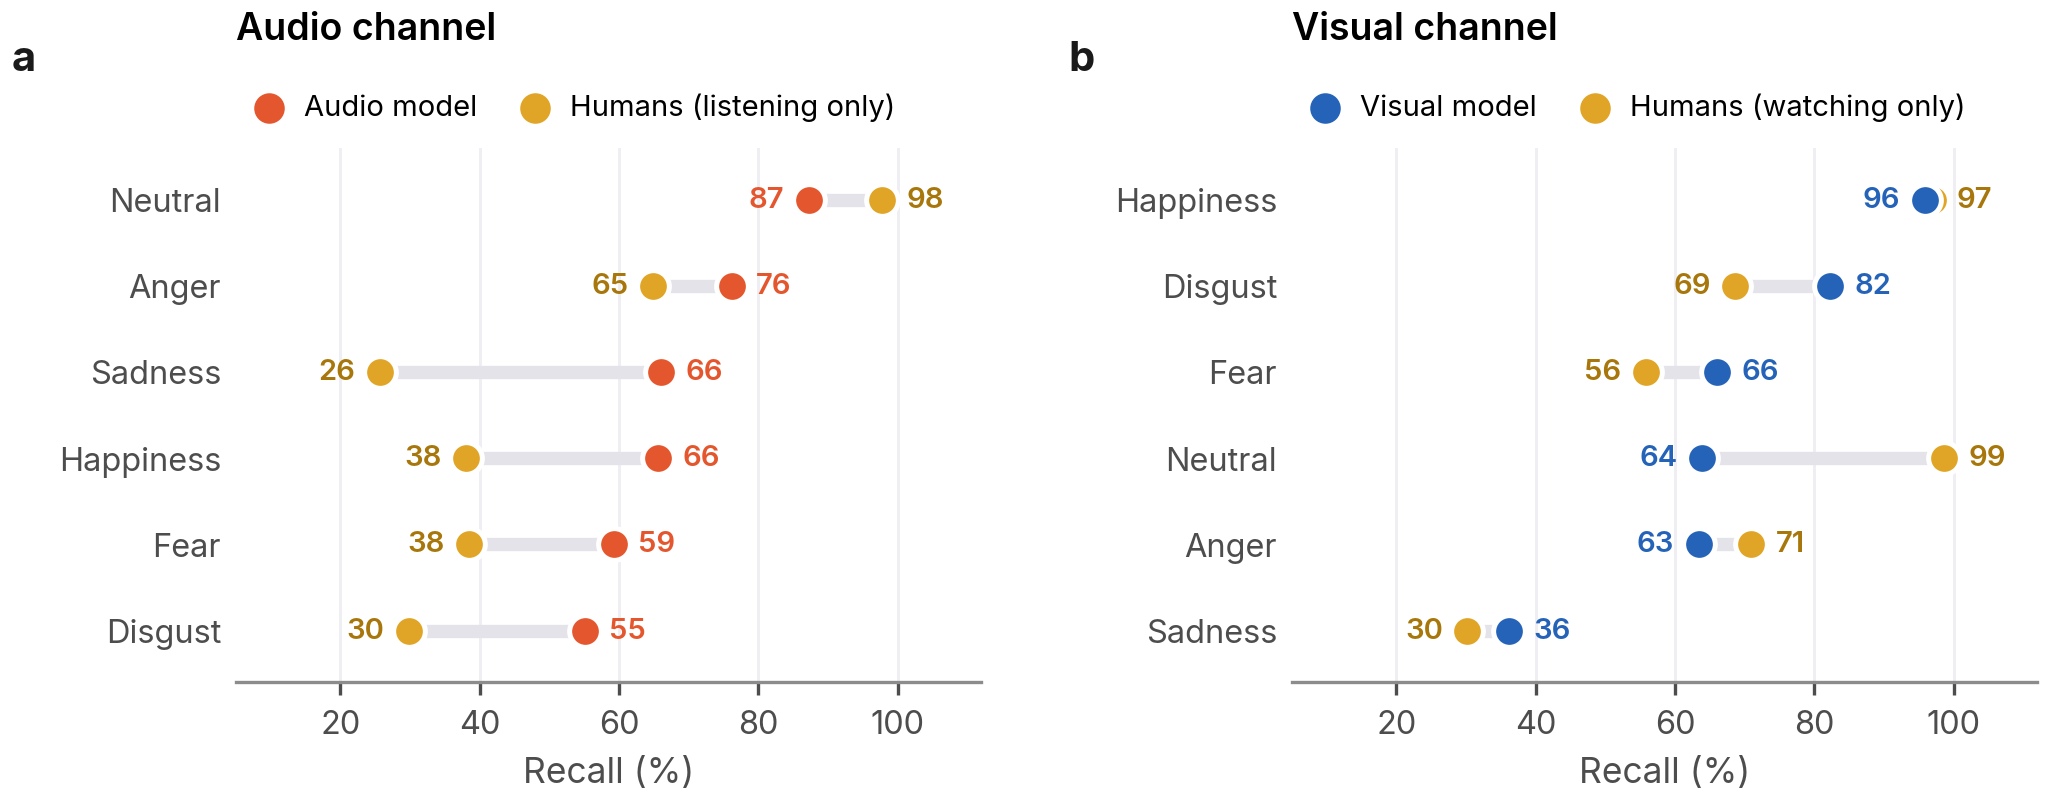

In [12]:
lab = dict(zip(CODES, EMO))
HUMC, HUMT = "#e0a526", "#a8770c"
fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.85), sharex=True)
for k, (ax, mcol, hcol, col, title, mname, hname) in enumerate([
        (axs[0], "Audio model", "Humans, voice only", AUD, "Audio channel", "Audio model", "Humans (listening only)"),
        (axs[1], "Visual model", "Humans, face only", VIS, "Visual channel", "Visual model", "Humans (watching only)")]):
    order = acc[mcol].sort_values().index
    y = np.arange(len(order))
    for yi, e in zip(y, order):
        m, h = acc.loc[e, mcol], acc.loc[e, hcol]
        ax.plot([h, m], [yi, yi], color="#e4e3ea", lw=3.2, zorder=1)
        ax.scatter(m, yi, s=58, color=col, zorder=4, edgecolor="white", lw=1.2)
        ax.scatter(h, yi, s=58, color=HUMC, zorder=3, edgecolor="white", lw=1.2)
        lo, hi = (m, h) if m < h else (h, m)
        ax.text(lo - 3.5, yi, f"{lo:.0f}", ha="right", va="center", fontsize=7, fontweight="semibold",
                color=col if lo == m else HUMT)
        ax.text(hi + 3.5, yi, f"{hi:.0f}", ha="left", va="center", fontsize=7, fontweight="semibold",
                color=col if hi == m else HUMT)
    ax.set_yticks(y, [lab[e] for e in order])
    ax.set_xlim(5, 112); ax.set_xticks([20, 40, 60, 80, 100]); ax.set_ylim(-0.6, 5.6)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True, color="#efeff3")
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Recall (%)")
    ax.set_title(title, pad=26)
    ax.scatter([], [], s=40, color=col, label=mname); ax.scatter([], [], s=40, color=HUMC, label=hname)
    ax.legend(loc="lower left", bbox_to_anchor=(-0.03, 1.0), ncol=2, fontsize=7, handletextpad=0.2, columnspacing=1.0)
    panel(ax, "ab"[k], x=-0.3, y=1.13)
fig.tight_layout(w_pad=2.5)
fig.savefig(OUT / "fig5_difficulty.png", facecolor="white")

## Figure 6: which modality is more useful (RQ3)

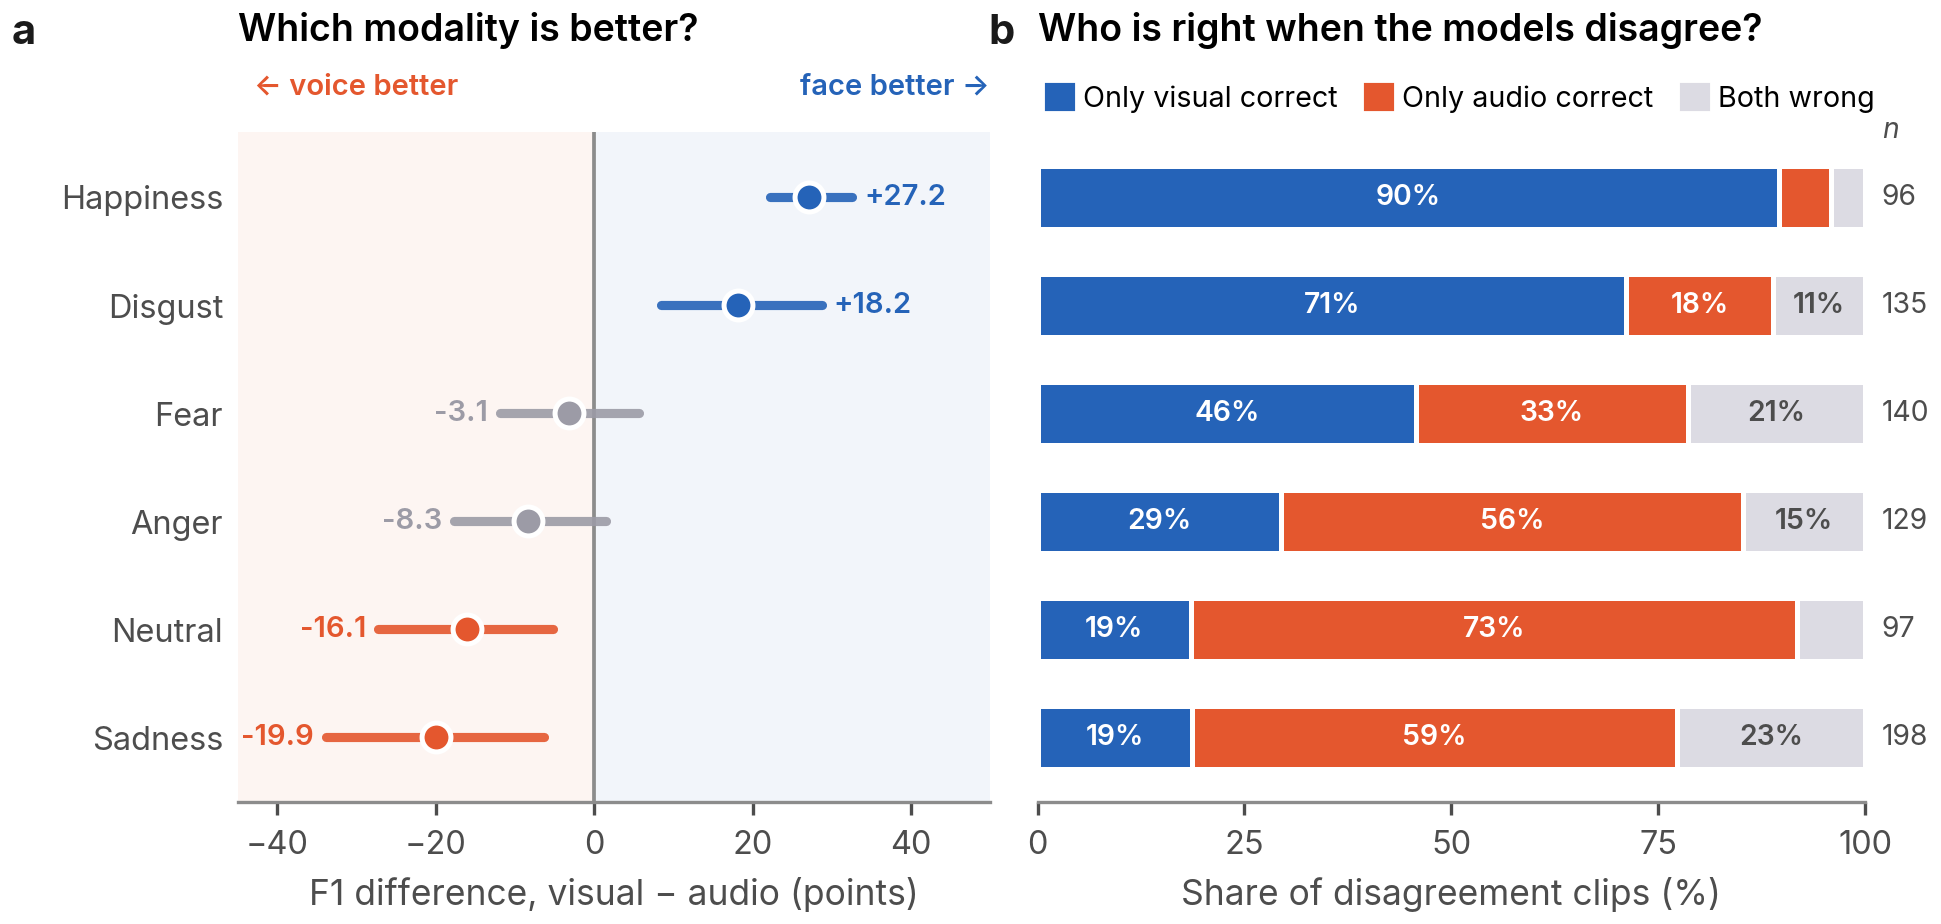

In [13]:
from matplotlib.patches import Patch
r = r3
lab = dict(zip(CODES, EMO))
order = r.f1_diff_v_minus_a.sort_values().index      # bottom = most audio-favoured
y = np.arange(len(order))
NEU = "#9c9ba6"
fig = plt.figure(figsize=(7.0, 2.9))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1], wspace=0.06)
axa, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# (a) forest plot of F1 difference
axa.axvspan(-45, 0, color=AUD, alpha=0.06, lw=0); axa.axvspan(0, 50, color=VIS, alpha=0.06, lw=0)
axa.axvline(0, color=INK3, lw=0.9)
for yi, e in zip(y, order):
    d, lo, hi = r.loc[e, "f1_diff_v_minus_a"] * 100, r.loc[e, "ci_low"] * 100, r.loc[e, "ci_high"] * 100
    sig = r.loc[e, "mcnemar_p_holm"] < 0.05 and (lo > 0 or hi < 0)
    col = (VIS if d > 0 else AUD) if sig else NEU
    axa.plot([lo, hi], [yi, yi], color=col, lw=2.2, solid_capstyle="round", alpha=0.9)
    axa.scatter(d, yi, s=48, color=col, zorder=3, edgecolor="white", lw=1.2)
    axa.text(hi + 1.5 if d > 0 else lo - 1.5, yi, f"{d:+.1f}", ha="left" if d > 0 else "right", va="center",
             fontsize=7, color=col, fontweight="semibold")
axa.set_yticks(y, [lab[e] for e in order]); axa.set_xlim(-45, 50); axa.set_ylim(-0.6, 5.6)
axa.set_xticks([-40, -20, 0, 20, 40])
axa.grid(axis="y", visible=False); axa.grid(axis="x", visible=False)
axa.spines["left"].set_visible(False); axa.tick_params(axis="y", length=0)
axa.set_xlabel("F1 difference, visual − audio (points)")
axa.text(-43, 5.95, "← voice better", fontsize=7, color=AUD, fontweight="semibold")
axa.text(50, 5.95, "face better →", fontsize=7, color=VIS, fontweight="semibold", ha="right")
axa.set_title("Which modality is better?", pad=22)
panel(axa, "a", x=-0.3, y=1.12)

# (b) who is right when the models disagree
vis = r.loc[order, "only_visual_right"] / r.loc[order, "n_dis"] * 100
aud = r.loc[order, "only_audio_right"] / r.loc[order, "n_dis"] * 100
nei = r.loc[order, "dis_neither"] / r.loc[order, "n_dis"] * 100
for yi, e in zip(y, order):
    left = 0
    for v, col, tc in [(vis[e], VIS, "white"), (aud[e], AUD, "white"), (nei[e], "#dcdbe3", INK2)]:
        axb.barh(yi, v, 0.58, left=left, color=col, edgecolor="white", lw=1.2)
        if v >= 9:
            axb.text(left + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=6.8, color=tc, fontweight="semibold")
        left += v
    axb.text(102, yi, f"{int(r.loc[e, 'n_dis'])}", va="center", fontsize=6.8, color=INK2)
axb.text(102, 5.55, "n", fontsize=6.8, color=INK2, fontstyle="italic")
axb.set_yticks(y, []); axb.set_xlim(0, 100); axb.set_ylim(-0.6, 5.6); axb.set_xticks([0, 25, 50, 75, 100])
axb.grid(False); axb.spines["left"].set_visible(False); axb.tick_params(axis="y", length=0)
axb.set_xlabel("Share of disagreement clips (%)")
axb.set_title("Who is right when the models disagree?", pad=22)
axb.legend(handles=[Patch(color=VIS, label="Only visual correct"), Patch(color=AUD, label="Only audio correct"),
                    Patch(color="#dcdbe3", label="Both wrong")], loc="lower left", bbox_to_anchor=(-0.02, 0.99),
           ncol=3, fontsize=6.9, handlelength=0.9, handleheight=0.9, handletextpad=0.35, columnspacing=1.0)
panel(axb, "b", x=-0.06, y=1.12)
fig.savefig(OUT / "fig6_modality.png", facecolor="white")

## Figure 7: speakers (RQ4)

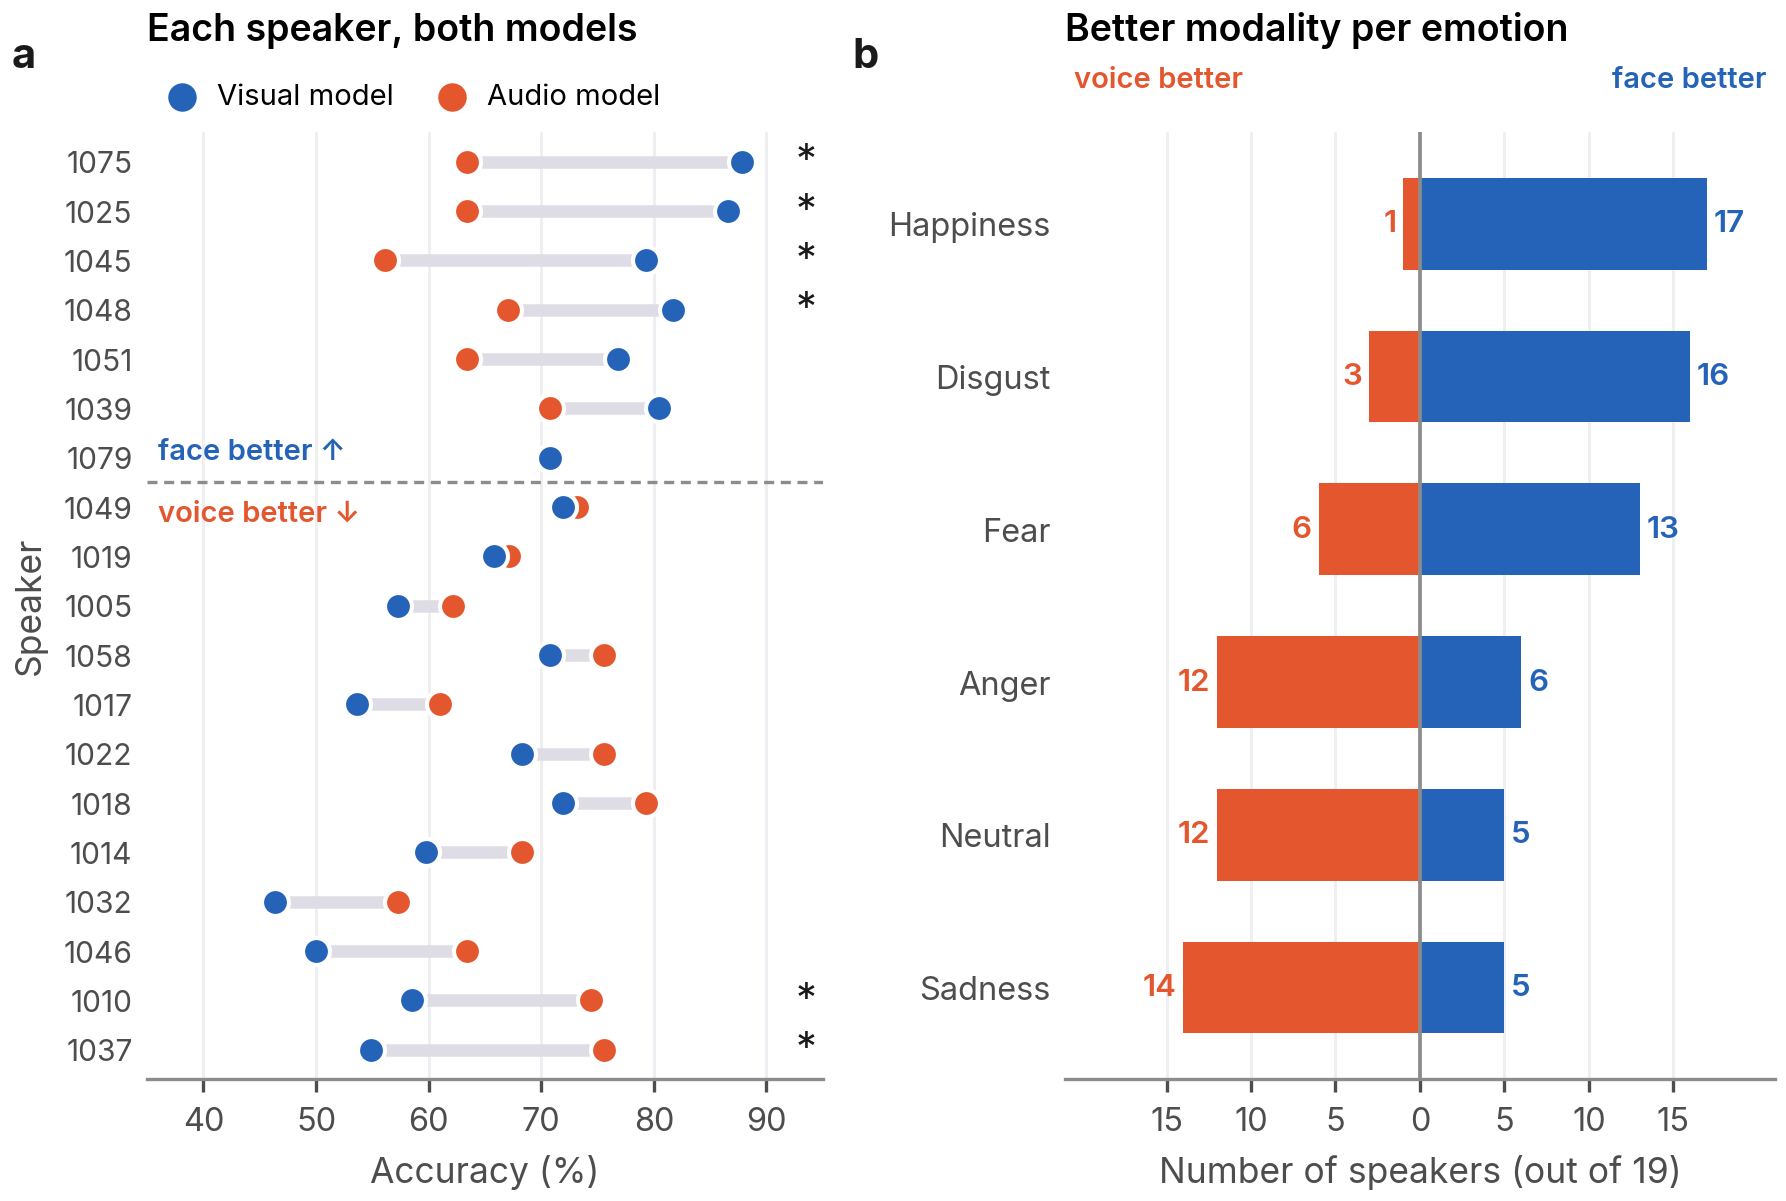

In [14]:
sp = sp.sort_values("diff_v_minus_a").reset_index(drop=True)
cons = cons.loc[CODES]
lab = dict(zip(CODES, EMO))
n = len(sp); y = np.arange(n)

fig = plt.figure(figsize=(7.0, 4.1))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.05], wspace=0.35)
axa, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# (a) per-speaker accuracy
for yi, r in sp.iterrows():
    axa.plot([r.acc_a * 100, r.acc_v * 100], [yi, yi], color="#dedde6", lw=3, zorder=1)
    axa.scatter(r.acc_a * 100, yi, s=42, color=AUD, zorder=3, edgecolor="white", lw=1)
    axa.scatter(r.acc_v * 100, yi, s=42, color=VIS, zorder=3, edgecolor="white", lw=1)
    if r.mcnemar_p < 0.05:
        axa.text(93.5, yi, "*", ha="center", va="center", fontsize=10, color=INK)
n_aud = int((sp.diff_v_minus_a < 0).sum())
axa.axhline(n_aud - 0.5, color=INK3, lw=0.8, ls=(0, (3, 2)))
axa.text(36, n_aud - 0.5 + 0.35, "face better ↑", fontsize=7, color=VIS, fontweight="semibold", va="bottom", ha="left")
axa.text(36, n_aud - 0.5 - 0.35, "voice better ↓", fontsize=7, color=AUD, fontweight="semibold", va="top", ha="left")
axa.set_yticks(y, [f"{int(s)}" for s in sp.Speaker], fontsize=7.2)
axa.set_xlim(35, 95); axa.set_ylim(-0.6, n - 0.4); axa.set_xticks([40, 50, 60, 70, 80, 90])
axa.grid(axis="y", visible=False); axa.grid(axis="x", visible=True, color="#efeff3")
axa.spines["left"].set_visible(False); axa.tick_params(axis="y", length=0)
axa.set_ylabel("Speaker")
axa.set_xlabel("Accuracy (%)")
axa.set_title("Each speaker, both models", pad=22)
axa.scatter([], [], s=34, color=VIS, label="Visual model"); axa.scatter([], [], s=34, color=AUD, label="Audio model")
axa.legend(loc="lower left", bbox_to_anchor=(-0.03, 0.995), ncol=2, fontsize=7, handletextpad=0.2, columnspacing=1.0)
panel(axa, "a", x=-0.2, y=1.06)

# (b) per emotion: number of speakers for whom face / voice is better
order = (cons.visual_better - cons.audio_better).sort_values().index
yb = np.arange(len(order))
for yi, e in zip(yb, order):
    v, a, t = cons.loc[e, "visual_better"], cons.loc[e, "audio_better"], cons.loc[e, "tie"]
    axb.barh(yi, v, 0.6, left=0, color=VIS)
    axb.barh(yi, -a, 0.6, left=0, color=AUD)
    if v: axb.text(v + 0.4, yi, f"{v}", va="center", ha="left", fontsize=7.5, color=VIS, fontweight="semibold")
    if a: axb.text(-a - 0.4, yi, f"{a}", va="center", ha="right", fontsize=7.5, color=AUD, fontweight="semibold")
    if not a: axb.text(-0.4, yi, "0", va="center", ha="right", fontsize=7.5, color=AUD, fontweight="semibold")
axb.axvline(0, color=INK3, lw=0.9)
axb.set_yticks(yb, [lab[e] for e in order]); axb.set_xlim(-21, 21); axb.set_ylim(-0.6, len(order) - 0.4)
axb.set_xticks([-15, -10, -5, 0, 5, 10, 15], ["15", "10", "5", "0", "5", "10", "15"])
axb.grid(axis="y", visible=False); axb.grid(axis="x", visible=True, color="#efeff3")
axb.spines["left"].set_visible(False); axb.tick_params(axis="y", length=0)
axb.set_xlabel("Number of speakers (out of 19)")
axb.text(-20.5, len(order) - 0.15, "voice better", fontsize=7, color=AUD, fontweight="semibold", va="bottom")
axb.text(20.5, len(order) - 0.15, "face better", fontsize=7, color=VIS, fontweight="semibold", va="bottom", ha="right")
axb.set_title("Better modality per emotion", pad=22)
panel(axb, "b", x=-0.3, y=1.06)
fig.savefig(OUT / "fig7_speakers.png", facecolor="white")

## Figure 8: calibration and fusion (RQ5)

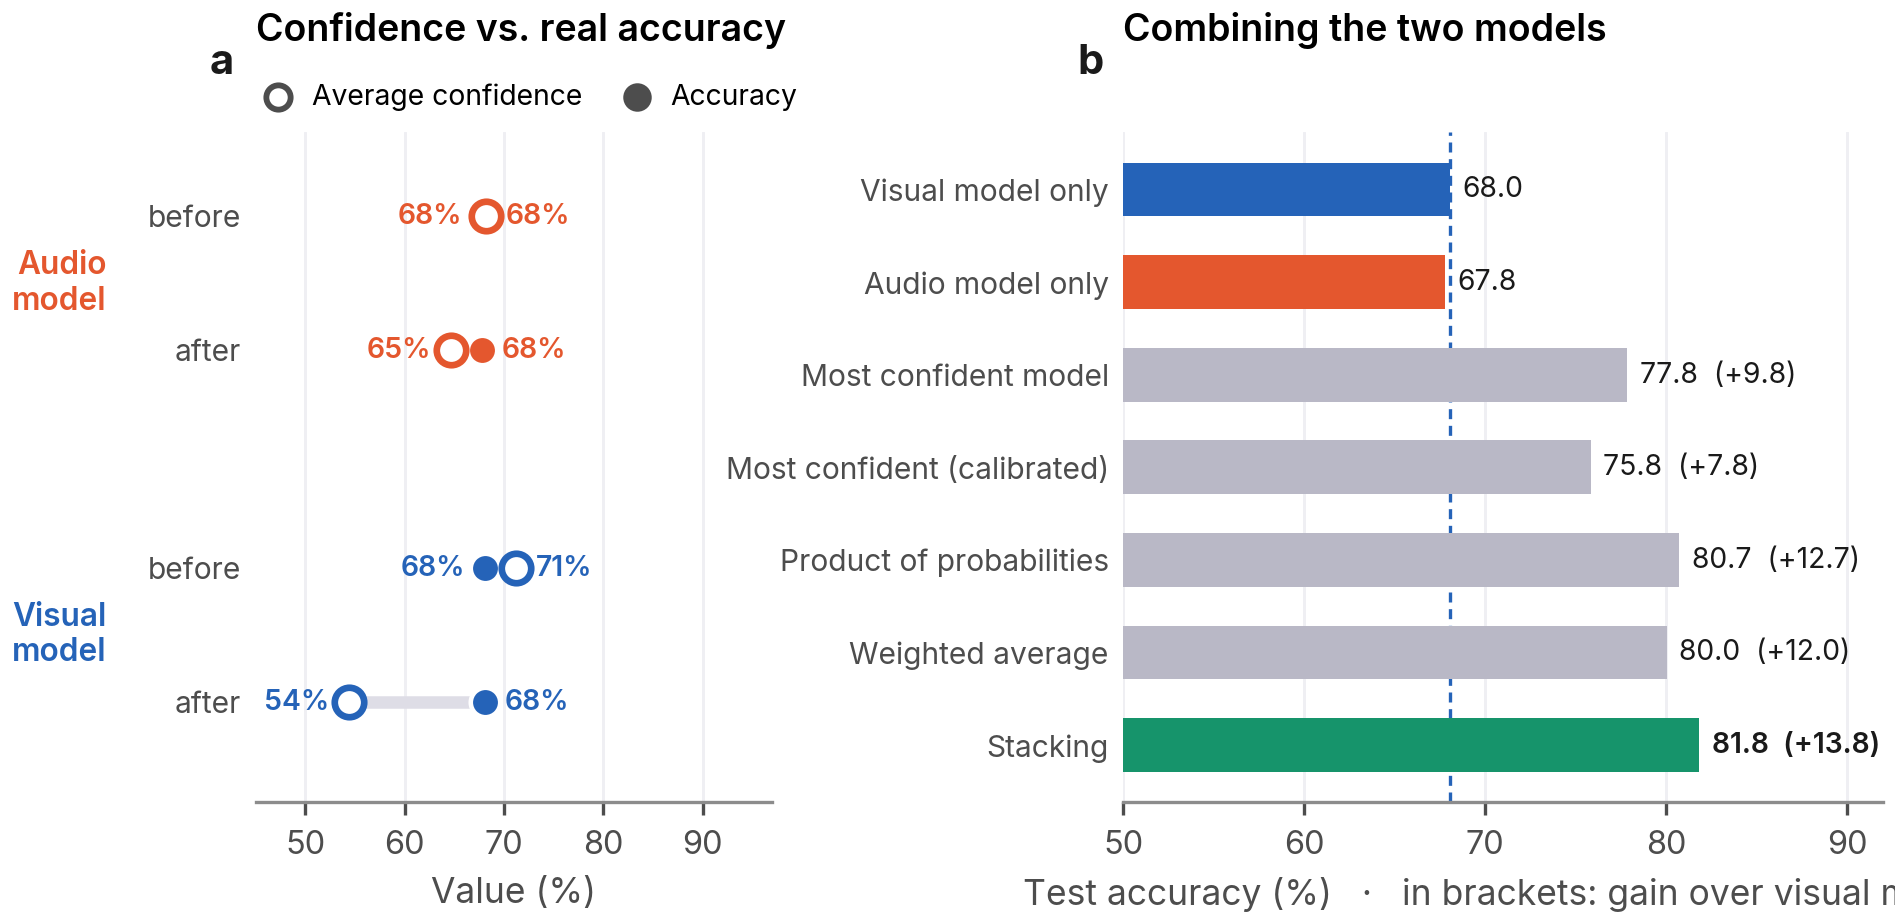

In [15]:
c = {(r.model, r.stage): r for r in cal.itertuples()}

fig = plt.figure(figsize=(7.0, 2.9))
gs = fig.add_gridspec(1, 2, width_ratios=[0.85, 1.25], wspace=0.55)

# (a) confidence vs accuracy, before / after calibration
ax = fig.add_subplot(gs[0])
groups = [("Audio", AUD), ("Visual", VIS)]
ypos = {("Audio", "raw"): 3, ("Audio", "calibrated"): 2.2, ("Visual", "raw"): 0.9, ("Visual", "calibrated"): 0.1}
for (m, col) in groups:
    for st in ("raw", "calibrated"):
        r = c[(m, st)]; yv = ypos[(m, st)]
        conf, acc = r.mean_conf * 100, r.accuracy * 100
        ax.plot([acc, conf], [yv, yv], color="#dedde6", lw=3, zorder=1)
        ax.scatter(acc, yv, s=50, color=col, zorder=3, edgecolor="white", lw=1.1)
        ax.scatter(conf, yv, s=50, facecolor="white", edgecolor=col, lw=1.6, zorder=3)
        lo, hi = sorted([acc, conf])
        ax.text(hi + 2, yv, f"{conf:.0f}%" if hi == conf else f"{acc:.0f}%", va="center", fontsize=6.8,
                color=col, fontweight="semibold")
        ax.text(lo - 2, yv, f"{acc:.0f}%" if lo == acc else f"{conf:.0f}%", va="center", ha="right", fontsize=6.8,
                color=col, fontweight="semibold")
ax.set_yticks([3, 2.2, 0.9, 0.1], ["before", "after", "before", "after"], fontsize=7.2)
ax.text(30, 2.6, "Audio\nmodel", ha="right", va="center", fontsize=7.6, fontweight="semibold", color=AUD,
        transform=ax.transData, clip_on=False)
ax.text(30, 0.5, "Visual\nmodel", ha="right", va="center", fontsize=7.6, fontweight="semibold", color=VIS,
        clip_on=False)
ax.set_xlim(45, 97); ax.set_ylim(-0.5, 3.5); ax.set_xticks([50, 60, 70, 80, 90])
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True, color="#efeff3")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Value (%)")
ax.set_title("Confidence vs. real accuracy", pad=22)
ax.scatter([], [], s=34, facecolor="white", edgecolor=INK2, lw=1.4, label="Average confidence")
ax.scatter([], [], s=34, color=INK2, label="Accuracy")
ax.legend(loc="lower left", bbox_to_anchor=(-0.06, 0.995), ncol=2, fontsize=6.8, handletextpad=0.2, columnspacing=0.9)
panel(ax, "a", x=-0.09, y=1.075)

# (b) fusion methods
ax = fig.add_subplot(gs[1])
rows = [("Visual only", "Visual model only", VIS),
        ("Audio only", "Audio model only", AUD),
        ("Most confident", "Most confident model", "#b9b8c6"),
        ("Most confident (cal.)", "Most confident (calibrated)", "#b9b8c6"),
        ("Product", "Product of probabilities", "#b9b8c6"),
        ("Weighted average", "Weighted average", "#b9b8c6"),
        ("Stacking", "Stacking", FUS)]
yy = np.arange(len(rows))[::-1]
base = res.loc["Visual only", "accuracy"] * 100
for yi, (key, lab, col) in zip(yy, rows):
    acc = res.loc[key, "accuracy"] * 100
    ax.barh(yi, acc - 50, 0.58, left=50, color=col)
    txt = f"{acc:.1f}"
    if key not in ("Visual only", "Audio only"):
        txt += f"  ({acc - base:+.1f})"
    ax.text(acc + 0.7, yi, txt, va="center", fontsize=6.8, color=INK,
            fontweight="semibold" if key.startswith("Stack") else "normal")
ax.axvline(base, color=VIS, lw=0.8, ls=(0, (3, 2)), zorder=0)
ax.set_yticks(yy, [l for _, l, _ in rows], fontsize=7.2)
ax.set_xlim(50, 92); ax.set_xticks([50, 60, 70, 80, 90])
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True, color="#efeff3")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Test accuracy (%)   ·   in brackets: gain over visual model")
ax.set_title("Combining the two models", pad=22)
panel(ax, "b", x=-0.06, y=1.075)
fig.savefig(OUT / "fig8_fusion.png", facecolor="white")

## Figure 1: overview of the study

A diagram (no data). It is drawn last, with matplotlib's default style.

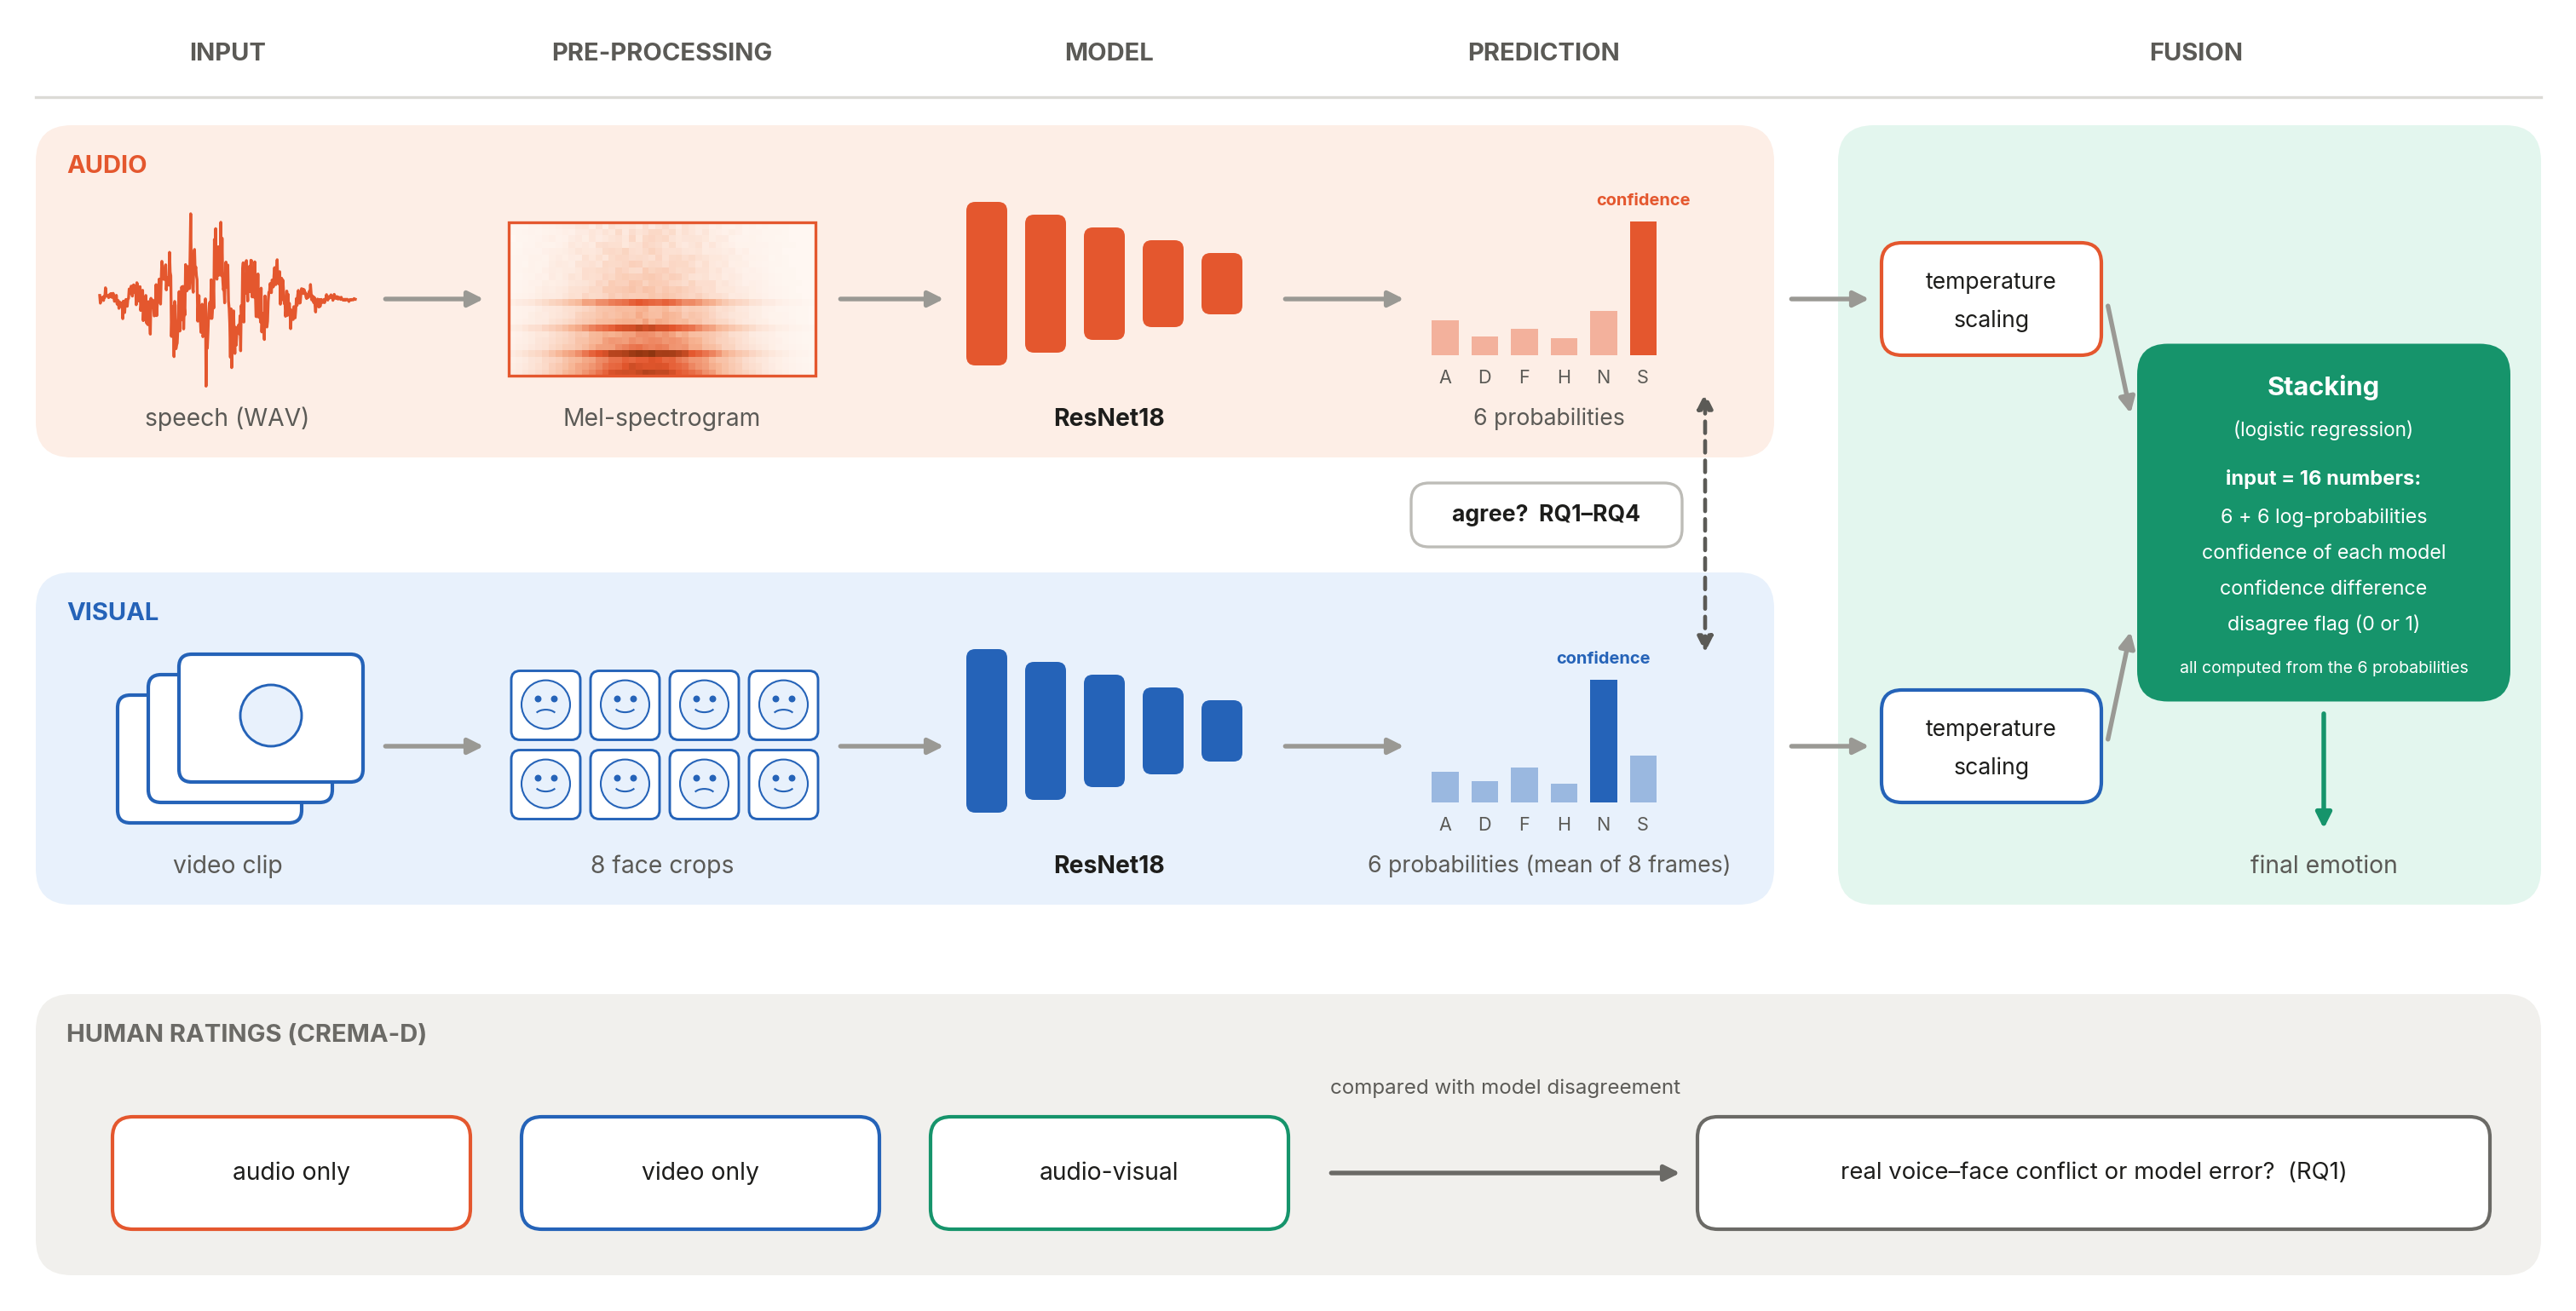

In [16]:
import textwrap
with plt.style.context("default"):
    plt.rcParams["font.family"] = "Inter"
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle, Arc
    from matplotlib.colors import LinearSegmentedColormap

    AUD, AUD_T = "#e4572e", "#fdeee6"
    VIS, VIS_T = "#2563b8", "#e8f1fc"
    FUS, FUS_T = "#16946b", "#e3f6ee"
    HUM, HUM_T = "#6b6a66", "#f1f0ed"
    INK, INK2, LINE = "#1d1d1b", "#5b5a56", "#9a9994"

    fig = plt.figure(figsize=(10, 5.05), dpi=300)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, 100); ax.set_ylim(1.5, 52); ax.axis("off")
    rng = np.random.default_rng(3)

    def rbox(x, y, w, h, fc, ec=None, lw=0, r=1.4, z=1):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
                                    fc=fc, ec=ec or fc, lw=lw, zorder=z))

    def arrow(x1, y1, x2, y2, c=LINE, lw=1.3, ls="-", both=False, z=3):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle=("<|-|>" if both else "-|>"),
                                     mutation_scale=9, color=c, lw=lw, linestyle=ls, zorder=z))

    def txt(x, y, s, size=8, c=INK, w="normal", ha="center", va="center", z=6):
        ax.text(x, y, s, fontsize=size, color=c, fontweight=w, ha=ha, va=va, zorder=z)

    for x, s in [(8.5, "Input"), (25.5, "Pre-processing"), (43, "Model"), (60, "Prediction"), (85.5, "Fusion")]:
        txt(x, 50.3, s.upper(), size=7, c=INK2, w="bold")
    ax.plot([1, 99], [48.6, 48.6], color="#dcdbd6", lw=0.8)

    LA, LV, LH = 34.5, 17.0, 13
    rbox(1, LA, 68, LH, AUD_T); rbox(1, LV, 68, LH, VIS_T)
    txt(2.2, LA + LH - 1.6, "AUDIO", size=7, c=AUD, w="bold", ha="left")
    txt(2.2, LV + LH - 1.6, "VISUAL", size=7, c=VIS, w="bold", ha="left")
    ca, cv = LA + LH / 2 - 0.3, LV + LH / 2 - 0.3

    # audio input waveform
    t = np.linspace(0, 1, 400)
    env = np.exp(-((t - 0.45) / 0.28) ** 2)
    wave = env * (np.sin(2 * np.pi * 9 * t) * 0.6 + rng.normal(0, 0.35, t.size)) * 2.6
    ax.plot(3.5 + t * 10, ca + wave, color=AUD, lw=0.8, zorder=4)
    txt(8.5, LA + 1.5, "speech (WAV)", size=6.8, c=INK2)

    # visual input film frames
    for k in range(3):
        x0, y0 = 4.2 + k * 1.2, cv - 3.0 + k * 0.8
        rbox(x0, y0, 7.2, 5.0, "white", VIS, lw=1.0, r=0.5, z=3 + k)
        ax.add_patch(Circle((x0 + 3.6, y0 + 2.6), 1.2, fc=VIS_T, ec=VIS, lw=0.7, zorder=3 + k))
    txt(8.5, LV + 1.5, "video clip", size=6.8, c=INK2)

    # mel spectrogram
    spec = np.zeros((24, 46))
    for j in range(46):
        e = np.exp(-((j - 20) / 12) ** 2)
        spec[:, j] = e * np.exp(-np.arange(24) / 9) + rng.uniform(0, .12, 24) * e
        for f0 in (3, 7, 11):
            spec[f0, j] += 0.5 * e
    cm = LinearSegmentedColormap.from_list("o", ["#fff7f2", "#f7b493", AUD, "#8f3510"])
    ax.imshow(spec, cmap=cm, origin="lower", extent=(19.5, 31.5, ca - 3.0, ca + 3.0), aspect="auto", zorder=4)
    ax.add_patch(Rectangle((19.5, ca - 3.0), 12, 6.0, fc="none", ec=AUD, lw=0.8, zorder=5))
    txt(25.5, LA + 1.5, "Mel-spectrogram", size=6.8, c=INK2)

    # 8 face crops
    for i in range(8):
        r_, c_ = divmod(i, 4)
        x0, y0 = 19.6 + c_ * 3.1, cv + 0.25 - r_ * 3.1
        rbox(x0, y0, 2.7, 2.7, "white", VIS, lw=0.7, r=0.35, z=4)
        cx, cy = x0 + 1.35, y0 + 1.38
        ax.add_patch(Circle((cx, cy), 0.95, fc=VIS_T, ec=VIS, lw=0.5, zorder=5))
        ax.plot([cx - .33, cx + .33], [cy + .25, cy + .25], ls="none", marker="o", ms=0.9, color=VIS, zorder=6)
        smile = i % 3 != 0
        ax.add_patch(Arc((cx, cy - (0.05 if smile else 0.45)), .85, .5,
                         theta1=200 if smile else 20, theta2=340 if smile else 160, color=VIS, lw=0.5, zorder=6))
    txt(25.5, LV + 1.5, "8 face crops", size=6.8, c=INK2)

    for (y, col) in ((ca, AUD), (cv, VIS)):
        for k, hh in enumerate([6.4, 5.4, 4.4, 3.4, 2.4]):
            rbox(37.4 + k * 2.3, y + 0.6 - hh / 2, 1.6, hh, col, r=0.35, z=4)
        txt(43, (LA if col == AUD else LV) + 1.5, "ResNet18", size=6.8, c=INK, w="bold")

    emos = ["A", "D", "F", "H", "N", "S"]
    pa = [0.12, 0.05, 0.08, 0.04, 0.16, 0.55]
    pv = [0.10, 0.06, 0.12, 0.05, 0.50, 0.17]
    for (y, col, p, lab) in ((ca, AUD, pa, "6 probabilities"), (cv, VIS, pv, "6 probabilities (mean of 8 frames)")):
        base = y - 2.2
        for k, val in enumerate(p):
            x0 = 55.6 + k * 1.55
            ax.add_patch(Rectangle((x0, base), 1.05, 0.3 + val * 9, fc=col, alpha=(1 if val == max(p) else 0.4),
                                   ec="none", zorder=4))
            txt(x0 + 0.52, base - 0.9, emos[k], size=5.2, c=INK2)
        txt(60.2, (LA if col == AUD else LV) + 1.5, lab, size=6.4, c=INK2)
        kx = int(np.argmax(p)); top = base + 0.3 + max(p) * 9
        txt(55.6 + kx * 1.55 + 0.52, top + 0.8, "confidence", size=4.8, c=col, w="bold")

    for y in (ca, cv):
        arrow(14.4, y, 18.8, y); arrow(32.2, y, 36.8, y); arrow(49.6, y, 54.8, y)

    gy = (LV + LH + LA) / 2
    arrow(66.3, cv + 3.4, 66.3, ca - 3.4, c=INK2, lw=1.1, ls=(0, (3, 2)), both=True)
    rbox(54.8, gy - 1.25, 10.6, 2.5, "white", "#bdbcb7", lw=0.8, r=0.7, z=5)
    txt(60.1, gy, "agree?  RQ1–RQ4", size=6.4, c=INK, w="bold")

    rbox(71.5, LV, 27.5, LA + LH - LV, FUS_T)
    for y, col in ((ca, AUD), (cv, VIS)):
        rbox(73.2, y - 2.2, 8.6, 4.4, "white", col, lw=1.0, r=0.8, z=4)
        txt(77.5, y + 0.65, "temperature", size=6.4); txt(77.5, y - 0.85, "scaling", size=6.4)
        arrow(69.4, y, 73.0, y)
    fy = (ca + cv) / 2
    rbox(83.2, fy - 7.0, 14.6, 14.0, FUS, r=1.2, z=4)
    txt(90.5, fy + 5.3, "Stacking", size=7.4, c="white", w="bold")
    txt(90.5, fy + 3.6, "(logistic regression)", size=5.4, c="white")
    txt(90.5, fy + 1.7, "input = 16 numbers:", size=5.7, c="white", w="bold")
    txt(90.5, fy + 0.2, "6 + 6 log-probabilities", size=5.6, c="white")
    txt(90.5, fy - 1.2, "confidence of each model", size=5.6, c="white")
    txt(90.5, fy - 2.6, "confidence difference", size=5.6, c="white")
    txt(90.5, fy - 4.0, "disagree flag (0 or 1)", size=5.6, c="white")
    txt(90.5, fy - 5.7, "all computed from the 6 probabilities", size=4.7, c="white", w="normal")
    arrow(82.0, ca, 83.0, fy + 4.0); arrow(82.0, cv, 83.0, fy - 4.0)
    arrow(90.5, fy - 7.2, 90.5, LV + 2.7, c=FUS)
    txt(90.5, LV + 1.5, "final emotion", size=6.8, c=INK2)

    # human ratings strip
    HY, HH = 2.5, 11
    rbox(1, HY, 98, HH, HUM_T)
    txt(2.2, HY + HH - 1.6, "HUMAN RATINGS (CREMA-D)", size=7, c=HUM, w="bold", ha="left")
    for k, (s, col) in enumerate([("audio only", AUD), ("video only", VIS), ("audio-visual", FUS)]):
        x0 = 4 + k * 16
        rbox(x0, HY + 1.8, 14, 4.4, "white", col, lw=1.0, r=0.8, z=4)
        txt(x0 + 7, HY + 4.0, s, size=6.8)
    rbox(66, HY + 1.8, 31, 4.4, "white", HUM, lw=1.0, r=0.8, z=4)
    txt(81.5, HY + 4.0, "real voice–face conflict or model error?  (RQ1)", size=6.6)
    arrow(51.4, HY + 4.0, 65.6, HY + 4.0, c=HUM)
    txt(58.5, HY + 7.3, "compared with model disagreement", size=5.8, c=INK2)

    fig.savefig(OUT / "fig1_overview.png", facecolor="white")